# 🚀 Модуль 7. Урок 1. Фреймворк A/B тестирования: MDE, статистическая мощность и расчет выборки

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_07_ab_testing/lesson_01_ab_testing_framework_and_mde.ipynb)

## 📌 Бизнес-контекст и методология
Самая частая ошибка в A/B тестировании — запуск теста без предварительного расчета размера выборки. 
Если выборка слишком мала, тест не имеет достаточной статистической мощности ($1-\beta = 80\%$) и пропустит реальный бизнес-эффект (ошибка II рода). 
MDE (Minimum Detectable Effect) — это минимальный прирост метрики, который тест способен надежно зафиксировать.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Рассчитаем необходимый размер выборки для базовой конверсии 8.5% при разных уровнях относительного MDE (от +5% до +20%).

In [2]:
from scipy import stats
import numpy as np

def calculate_sample_size(p_base, mde_relative, alpha=0.05, power=0.80):
    """Формула Эвана Миллера для расчета размера выборки на одну группу."""
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_beta = stats.norm.ppf(power)
    p_treat = p_base * (1 + mde_relative)
    p_pooled = (p_base + p_treat) / 2
    
    numerator = (z_alpha * np.sqrt(2 * p_pooled * (1 - p_pooled)) + 
                 z_beta * np.sqrt(p_base * (1 - p_base) + p_treat * (1 - p_treat))) ** 2
    denominator = (p_treat - p_base) ** 2
    return int(np.ceil(numerator / denominator))

base_cr = 0.085  # 8.5%
for mde_rel in [0.05, 0.10, 0.15, 0.20]:
    n = calculate_sample_size(base_cr, mde_rel)
    print(f"MDE: +{mde_rel*100:4.1f}% (CR {base_cr*100:.1f}% -> {base_cr*(1+mde_rel)*100:.2f}%) -> Требуется {n:6,d} пользователей на группу")

MDE: + 5.0% (CR 8.5% -> 8.93%) -> Требуется 69,121 пользователей на группу
MDE: +10.0% (CR 8.5% -> 9.35%) -> Требуется 17,660 пользователей на группу
MDE: +15.0% (CR 8.5% -> 9.78%) -> Требуется  8,017 пользователей на группу
MDE: +20.0% (CR 8.5% -> 10.20%) -> Требуется  4,603 пользователей на группу


### 📊 Визуализация: Кривые мощности (Power Curves) и Закон квадрата
Графики ниже наглядно показывают ключевой закон планирования A/B тестов:
**Чтобы поймать эффект в 2 раза меньше, выборку нужно увеличить в 4 раза!**

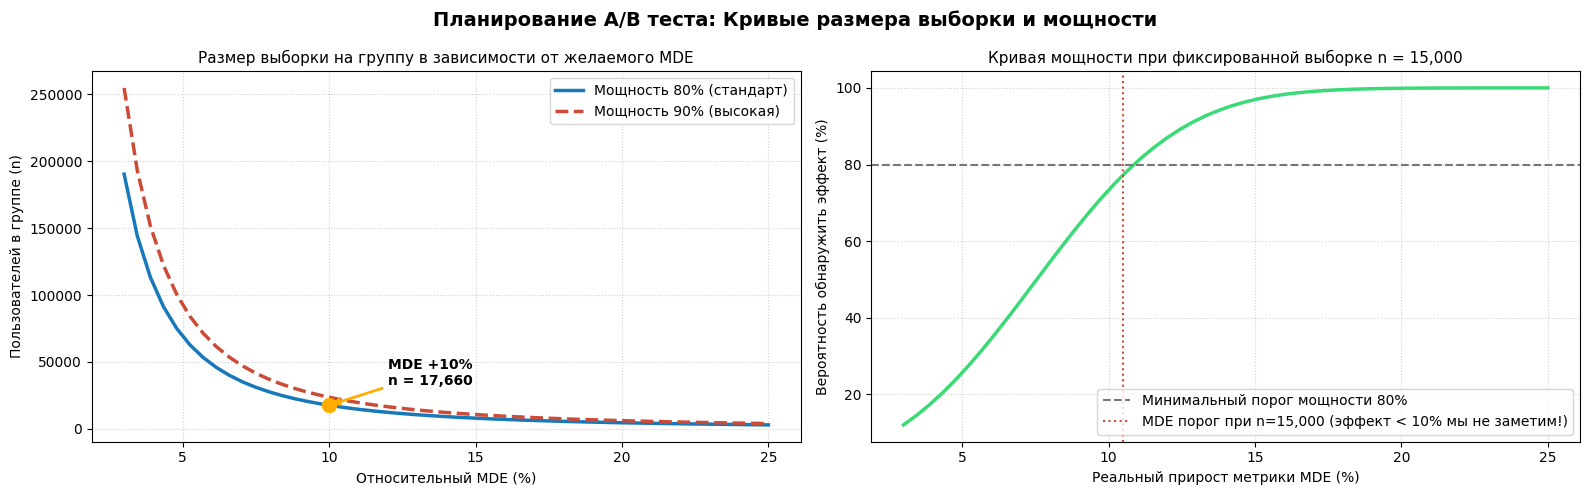

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Планирование A/B теста: Кривые размера выборки и мощности', fontsize=14, fontweight='bold')

# 1. Размер выборки vs Относительный MDE
ax1 = axes[0]
mde_range = np.linspace(0.03, 0.25, 50)
samples_80 = [calculate_sample_size(0.085, mde, power=0.80) for mde in mde_range]
samples_90 = [calculate_sample_size(0.085, mde, power=0.90) for mde in mde_range]

ax1.plot(mde_range * 100, samples_80, color='#1779ba', linewidth=2.5, label='Мощность 80% (стандарт)')
ax1.plot(mde_range * 100, samples_90, color='#cc4b37', linewidth=2.5, linestyle='--', label='Мощность 90% (высокая)')

n_10 = calculate_sample_size(0.085, 0.10)
ax1.scatter(10, n_10, color='#ffae00', s=100, zorder=5)
ax1.annotate(f'MDE +10%\nn = {n_10:,}', xy=(10, n_10), xytext=(12, n_10 + 15000),
             arrowprops=dict(arrowstyle="->", color='#ffae00', lw=2), fontweight='bold')

ax1.set_title('Размер выборки на группу в зависимости от желаемого MDE', fontsize=11)
ax1.set_xlabel('Относительный MDE (%)')
ax1.set_ylabel('Пользователей в группе (n)')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Мощность теста при фиксированной выборке n = 15,000
ax2 = axes[1]
n_fixed = 15000
z_alpha = stats.norm.ppf(1 - 0.05 / 2)
powers = []
for mde in mde_range:
    p_treat = base_cr * (1 + mde)
    se = np.sqrt(base_cr * (1 - base_cr) / n_fixed + p_treat * (1 - p_treat) / n_fixed)
    z_stat = (p_treat - base_cr) / se
    pwr = 1 - stats.norm.cdf(z_alpha - z_stat)
    powers.append(pwr * 100)

ax2.plot(mde_range * 100, powers, color='#3adb76', linewidth=2.5)
ax2.axhline(80, color='#767676', linestyle='--', label='Минимальный порог мощности 80%')
ax2.axvline(10.5, color='#cc4b37', linestyle=':', label='MDE порог при n=15,000 (эффект < 10% мы не заметим!)')
ax2.set_title(f'Кривая мощности при фиксированной выборке n = {n_fixed:,}', fontsize=11)
ax2.set_xlabel('Реальный прирост метрики MDE (%)')
ax2.set_ylabel('Вероятность обнаружить эффект (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет длительности теста в днях
Если в сутки интернет-магазин посещают 3,000 пользователей чекаута, за сколько полных дней тест наберет необходимую выборку для MDE = +10% (обе группы суммарно)?

In [4]:
### ВАШ КОД ЗДЕСЬ
daily_traffic = 3000
total_needed = n_10 * 2  # для двух групп (A и B)
test_days = int(np.ceil(total_needed / daily_traffic))

print(f"Всего нужно пользователей: {total_needed:,}")
print(f"Минимальная длительность теста: {test_days} полных дней ({test_days / 7:.1f} недель)")

assert test_days >= 7, "Тест обязан длиться минимум 1 полную неделю для учета сезонности"
print("✅ Тест успешно пройден!")

Всего нужно пользователей: 35,320
Минимальная длительность теста: 12 полных дней (1.7 недель)
✅ Тест успешно пройден!


### 💼 Золотое правило длительности теста:
Даже если калькулятор говорит, что выборка наберется за 2 дня, **никогда не останавливайте тест раньше полных 1-2 недель**. 
В противном случае вы получите искажение из-за дня недели (паттерны понедельника кардинально отличаются от субботы).